In [1]:
# ---------- CELL 1: imports and global style ----------
import os
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

plt.style.use("tableau-colorblind10")   # set once, before the rcParams below
plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
    "figure.dpi": 110,
    "savefig.dpi": 300,
})

CONFLICT_THRESHOLD = 0.3   # paragraphs with >= this share of conflict count as "Conflict"


In [2]:
# ---------- CELL 2: helper functions ----------
def style_axes(ax, title, xlabel=None, ylabel=None):
    """Horizontal light grid only, no vertical lines, no top/right frame."""
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.8)
    ax.grid(axis="x", visible=False)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#999999")
    ax.tick_params(axis="both", length=0)
    ax.set_title(title, pad=14)
    if xlabel is not None:
        ax.set_xlabel(xlabel, labelpad=8)
    if ylabel is not None:
        ax.set_ylabel(ylabel, labelpad=8)


def add_value_labels(ax, fmt="%.2f", fontsize=10):
    """Centered value labels above every bar."""
    for container in ax.containers:
        ax.bar_label(container, fmt=fmt, padding=2, fontsize=fontsize)


def grouped_bar(df, title, xlabel=None, ylabel=None, figsize=(9, 5),
                rotation=0, width=0.78, legend_title=None, legend_outside=True,
                label_fontsize=10):
    """Grouped bar chart from a DataFrame (index = x groups, columns = series)."""
    fig, ax = plt.subplots(figsize=figsize)
    df.plot(kind="bar", ax=ax, width=width, edgecolor="white", linewidth=0.8)
    style_axes(ax, title, xlabel, ylabel)
    plt.setp(ax.get_xticklabels(), rotation=rotation,
             ha="right" if rotation else "center")
    ymax = df.max().max()
    ax.set_ylim(0, ymax * 1.15)                 # headroom for the labels
    add_value_labels(ax, fontsize=label_fontsize)
    if legend_outside:
        ax.legend(title=legend_title, frameon=False,
                  loc="upper left", bbox_to_anchor=(1.01, 1))
    else:
        ax.legend(title=legend_title, frameon=False)
    fig.tight_layout()
    return fig, ax


def save_fig(fig, path):
    if path:
        os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
        fig.savefig(path, bbox_inches="tight")

In [3]:
# ---------- CELL 3: plot functions ----------
def plot_topics(df_topics, save_path):
    fig, ax = grouped_bar(
        df_topics,
        title="Tree Structure of Paragraphs per Topic",
        ylabel="Value per Paragraph",
        figsize=(7, 5),
        legend_title="Topic",
        legend_outside=False,
    )
    save_fig(fig, save_path)
    plt.show()


def plot_topics_confl(df_topics_confl, save_path):
    fig, ax = grouped_bar(
        df_topics_confl,
        title="Tree Structure of Conflict/Non-Conflict Paragraphs per Topic",
        xlabel="Nuclearity Mass (NM)",
        ylabel="Value per Paragraph",
        figsize=(11, 5),
        rotation=20,
        legend_title="Topic",
    )
    save_fig(fig, save_path)
    plt.show()


def plot_countries(df_countries, save_path):
    fig, ax = grouped_bar(
        df_countries,
        title="Tree Structure of Conflict and Non-Conflict Paragraphs per Country",
        xlabel="Nuclearity Mass (NM)",
        ylabel="Value per Paragraph",
        figsize=(12, 5),
        rotation=20,
        legend_title="Country",
    )
    save_fig(fig, save_path)
    plt.show()


def plot_countries_sm(df_countries, save_path):
    """NM2 only. x = countries, bars = Conflict vs. Non-Conflict."""
    df = df_countries.drop(["NM1_Conflict", "NM1_Non-Conflict"], axis=0)
    df = df.rename({"NM2_Conflict": "Conflict", "NM2_Non-Conflict": "Non-Conflict"}, axis=0)
    df = df.T                                    # countries on the x-axis; use df (no .T) for the old layout
    fig, ax = grouped_bar(
        df,
        title="Tree Structure of Conflict and Non-Conflict Paragraphs (NM2)",
        ylabel="Value per Paragraph (NM2)",
        figsize=(10, 5.5),
        rotation=25,
        legend_title=None,
        legend_outside=False,
    )
    save_fig(fig, save_path)
    plt.show()

In [4]:
# ---------- CELL 4: data preparation ----------
NM_COLS = ["NM1_para", "NM2_para"]


def split_conflict(df, threshold=CONFLICT_THRESHOLD):
    confl = df[df["propotion_conflict_para"] >= threshold]
    noconfl = df[df["propotion_conflict_para"] < threshold]
    return confl, noconfl


def mean_nm(df):
    return df[NM_COLS].mean().tolist()


def compare_topic(df_paragraphs, save_dir):
    df_ukr = df_paragraphs[df_paragraphs["filename"].str.contains("UNSC_2014")]
    df_wps = df_paragraphs[df_paragraphs["filename"].str.contains("UNSC_2016")]

    print("mean NM1 and NM2 values for Ukraine:\n", df_ukr[NM_COLS].mean(), "\n")
    print("mean NM1 and NM2 values for WPS:\n", df_wps[NM_COLS].mean(), "\n")

    df_topics = pd.DataFrame({"Ukraine": mean_nm(df_ukr), "WPS": mean_nm(df_wps)},
                             index=["NM1", "NM2"])
    plot_topics(df_topics, os.path.join(save_dir, "TS_topic.pdf") if save_dir else None)

    ukr_c, ukr_n = split_conflict(df_ukr)
    wps_c, wps_n = split_conflict(df_wps)
    print("Conflict-heavy / less conflict-heavy paragraphs")
    print("  Ukraine:", ukr_c.shape[0], "/", ukr_n.shape[0])
    print("  WPS:    ", wps_c.shape[0], "/", wps_n.shape[0])

    df_confl = pd.DataFrame(
        {"Ukraine": mean_nm(ukr_c) + mean_nm(ukr_n),
         "WPS": mean_nm(wps_c) + mean_nm(wps_n)},
        index=["NM1_Conflict", "NM2_Conflict", "NM1_Non-Conflict", "NM2_Non-Conflict"],
    ).sort_index()
    plot_topics_confl(df_confl, os.path.join(save_dir, "TS_topic_confl.pdf") if save_dir else None)


# display name -> substring searched in the filename column
COUNTRY_PATTERNS = {
    "China": "China",
    "France": "France",
    "Ukraine": "Ukraine",
    "Russian Federation": "Russian_Federation",
    "United Kingdom": "United_Kingdom_Of_Great_Britain_And_Northern_Ireland",
    "United States": "America",
}


def compare_countries(df_paragraphs, save_dir, patterns=COUNTRY_PATTERNS):
    data = {}
    for name, pattern in patterns.items():
        df_c = df_paragraphs[df_paragraphs["filename"].str.contains(pattern)]
        confl, noconfl = split_conflict(df_c)
        print(f"{name}: {confl.shape[0]} conflict / {noconfl.shape[0]} non-conflict paragraphs")
        data[name] = mean_nm(confl) + mean_nm(noconfl)

    df_countries = pd.DataFrame(
        data,
        index=["NM1_Conflict", "NM2_Conflict", "NM1_Non-Conflict", "NM2_Non-Conflict"],
    )
    # plot_countries(df_countries)   # all four rows, if wanted
    plot_countries_sm(df_countries,
                      os.path.join(save_dir, "TS_countries_sm.pdf") if save_dir else None)


mean NM1 and NM2 values for Ukraine:
 NM1_para    0.211741
NM2_para    0.067370
dtype: float64 

mean NM1 and NM2 values for WPS:
 NM1_para    0.259505
NM2_para    0.082826
dtype: float64 



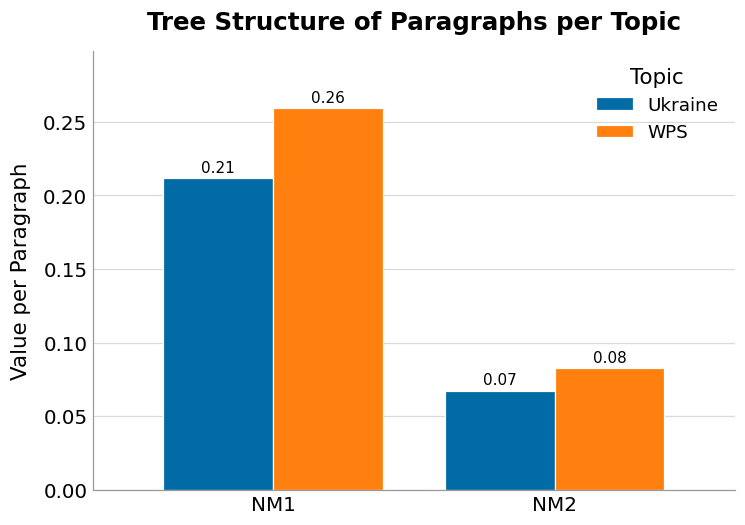

Conflict-heavy / less conflict-heavy paragraphs
  Ukraine: 194 / 277
  WPS:     17 / 129


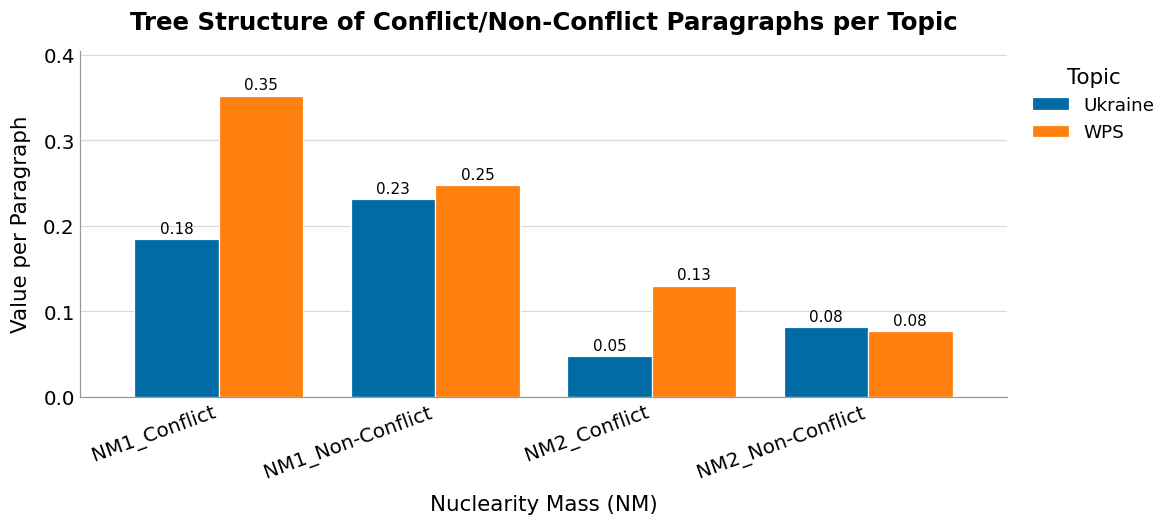

China: 4 conflict / 28 non-conflict paragraphs
France: 16 conflict / 38 non-conflict paragraphs
Ukraine: 37 conflict / 36 non-conflict paragraphs
Russian Federation: 29 conflict / 40 non-conflict paragraphs
United Kingdom: 17 conflict / 27 non-conflict paragraphs
United States: 33 conflict / 42 non-conflict paragraphs


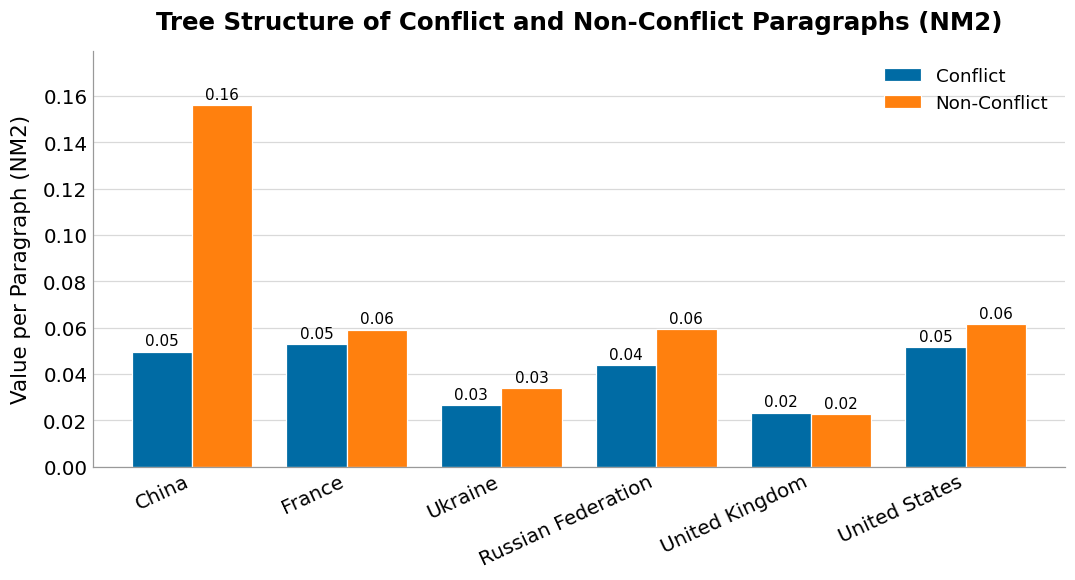

In [5]:
# ---------- CELL 5: load data and run ----------
table_nm_para = pd.read_csv("../data/output/nuclearity_mass_para.csv", index_col=[0])
table_nm_spch = pd.read_csv("../data/output/nuclearity_mass_speech.csv", index_col=[0])

SAVE_DIR = "../data/output/img/diss"     # set to None to skip saving

compare_topic(table_nm_para, SAVE_DIR)
compare_countries(table_nm_para, SAVE_DIR)
